## 1.📚 Importing Lipraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 2.📂 Loading Data

In [2]:
copy=pd.read_csv('cs-training.csv')

###### ما الذي يتعلمه البنك من هذه البيانات؟

يحاول البنك اكتشاف أنماط مثل:

هل العملاء ذوو DebtRatio المرتفعة أكثر عرضة للتعثر؟
هل انخفاض MonthlyIncome يزيد من خطر عدم السداد؟
هل كثرة مرات التأخر السابقة (30–59، 60–89، 90+ يومًا) تؤدي إلى تعثر مستقبلي؟
هل استخدام نسبة كبيرة من الحد الائتماني (RevolvingUtilizationOfUnsecuredLines) يرتبط بزيادة المخاطر؟
هل عدد القروض المفتوحة يؤثر على احتمال التعثر؟
هل العمر وعدد المعالين لهما تأثير على السلوك الائتماني؟
##### KPIs المناسبة لهذا المشروع
Default Rate: نسبة العملاء الذين تعثروا في السداد.
Average Debt Ratio: متوسط نسبة الديون إلى الدخل.
Average Monthly Income: متوسط الدخل الشهري.
Average Credit Utilization: متوسط استخدام الائتمان.
Average Number of Late Payments: متوسط عدد مرات التأخر في السداد.
Average Number of Open Loans: متوسط عدد القروض المفتوحة.
High-Risk Customer Rate: نسبة العملاء ذوي مؤشرات المخاطر المرتفعة.

## 3.🔍 Discovering Data

In [3]:
df=copy
df.head(10)

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0
5,6,0,0.213179,74,0,0.375607,3500.0,3,0,1,0,1.0
6,7,0,0.305682,57,0,5710.000000,NaN,8,0,3,0,0.0
7,8,0,0.754464,39,0,0.209940,3500.0,8,0,0,0,0.0
8,9,0,0.116951,27,0,46.000000,NaN,2,0,0,0,NaN
9,10,0,0.189169,57,0,0.606291,23684.0,9,0,4,0,2.0


In [4]:
df.columns

Index(['Unnamed: 0', 'SeriousDlqin2yrs',
       'RevolvingUtilizationOfUnsecuredLines', 'age',
       'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome',
       'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate',
       'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse',
       'NumberOfDependents'],
      dtype='object')

In [5]:
df.drop(columns='Unnamed: 0',inplace=True)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   NumberRealEstateLoansOrLines          150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    146076 non-null  float64
dtype

In [7]:
df.shape

(150000, 11)

In [8]:
df.isna().sum()

SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64

In [9]:
arr=['NumberOfOpenCreditLinesAndLoans','NumberOfTimes90DaysLate','NumberRealEstateLoansOrLines',
     'NumberOfTime60-89DaysPastDueNotWorse','NumberOfDependents','SeriousDlqin2yrs',
     'NumberOfTime30-59DaysPastDueNotWorse']
for col in arr:
    print("column is : ", col)
    print(df[col].unique())
    print("#"*80,"\n\n")


column is :  NumberOfOpenCreditLinesAndLoans
[13  4  2  5  7  3  8  9  6 10 14 22 17  1 15 31 12 21 11 19 18 26 20 23
  0 16 27 29 28 24 25 32 46 33 30 34 37 38 36 35 54 43 45 49 57 48 40 58
 51 52 39 41 56 42 47 50 44 53]
################################################################################ 


column is :  NumberOfTimes90DaysLate
[ 0  1  3  2  5  4 98 10  9  6  7  8 15 96 11 13 14 17 12]
################################################################################ 


column is :  NumberRealEstateLoansOrLines
[ 6  0  1  3  4  2  5  8  7  9 17 15 10 12 11 16 26 14 54 21 18 13 23 29
 25 19 20 32]
################################################################################ 


column is :  NumberOfTime60-89DaysPastDueNotWorse
[ 0  1  2  5  3 98  4  6  7  8 96 11  9]
################################################################################ 


column is :  NumberOfDependents
[ 2.  1.  0. nan  3.  4.  5.  6.  8.  7. 20. 10.  9. 13.]
###################################

In [10]:
df['MonthlyIncome']=df['MonthlyIncome'].fillna(df['MonthlyIncome'].median())
df['NumberOfDependents']=df['NumberOfDependents'].fillna(df['NumberOfDependents'].mode()[0])

In [11]:
df.describe()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
count,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,1.500000e+05,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000
mean,0.066840,6.048438,52.295207,0.421033,353.005076,6.418455e+03,8.452760,0.265973,1.018240,0.240387,0.737413
std,0.249746,249.755371,14.771866,4.192781,2037.818523,1.289040e+04,5.145951,4.169304,1.129771,4.155179,1.107021
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.029867,41.000000,0.000000,0.175074,3.903000e+03,5.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.154181,52.000000,0.000000,0.366508,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000
75%,0.000000,0.559046,63.000000,0.000000,0.868254,7.400000e+03,11.000000,0.000000,2.000000,0.000000,1.000000
max,1.000000,50708.000000,109.000000,98.000000,329664.000000,3.008750e+06,58.000000,98.000000,54.000000,98.000000,20.000000


In [12]:
cols = [
    'NumberOfTime30-59DaysPastDueNotWorse',
    'NumberOfTimes90DaysLate',
    'NumberOfTime60-89DaysPastDueNotWorse'
]

for col in cols:
    print(col)
    print(df[col].value_counts().head(15))
    print('-' * 40)

NumberOfTime30-59DaysPastDueNotWorse
NumberOfTime30-59DaysPastDueNotWorse
0     126018
1      16033
2       4598
3       1754
4        747
5        342
98       264
6        140
7         54
8         25
9         12
96         5
10         4
12         2
13         1
Name: count, dtype: int64
----------------------------------------
NumberOfTimes90DaysLate
NumberOfTimes90DaysLate
0     141662
1       5243
2       1555
3        667
4        291
98       264
5        131
6         80
7         38
8         21
9         19
10         8
96         5
11         5
13         4
Name: count, dtype: int64
----------------------------------------
NumberOfTime60-89DaysPastDueNotWorse
NumberOfTime60-89DaysPastDueNotWorse
0     142396
1       5731
2       1118
3        318
98       264
4        105
5         34
6         16
7          9
96         5
8          2
11         1
9          1
Name: count, dtype: int64
----------------------------------------


In [13]:
df[df['MonthlyIncome'] > 500000].shape

(12, 11)

In [14]:
df[df['NumberOfTimes90DaysLate']>20][['NumberOfTime30-59DaysPastDueNotWorse',
    'NumberOfTimes90DaysLate',
    'NumberOfTime60-89DaysPastDueNotWorse',]]



,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTimes90DaysLate,NumberOfTime60-89DaysPastDueNotWorse
1733,98,98,98
2286,98,98,98
3884,98,98,98
4417,98,98,98
4705,98,98,98
...,...,...,...
147774,98,98,98
149153,98,98,98
149239,98,98,98
149439,98,98,98


In [15]:
print (df[df['NumberOfTimes90DaysLate']>20]['NumberOfTimes90DaysLate'].unique())
print("*"*80)
print((df['NumberOfTimes90DaysLate']>20).sum()/df.shape[0])
df=df[df['NumberOfTimes90DaysLate']<20]
df=df[df['NumberOfTime30-59DaysPastDueNotWorse']<20]
df=df[df['NumberOfTime60-89DaysPastDueNotWorse']<20]

[98 96]
********************************************************************************
0.0017933333333333334


##### Invalid Delinquency Records

A total of 269 records (0.18% of the dataset) contained unusual values (96 and 98) in all three late-payment columns. These values are not realistic and are likely the result of data entry errors or invalid codes. Since they represent only a very small part of the dataset, these records were removed to improve data quality before training the machine learning model.


<Axes: ylabel='MonthlyIncome'>

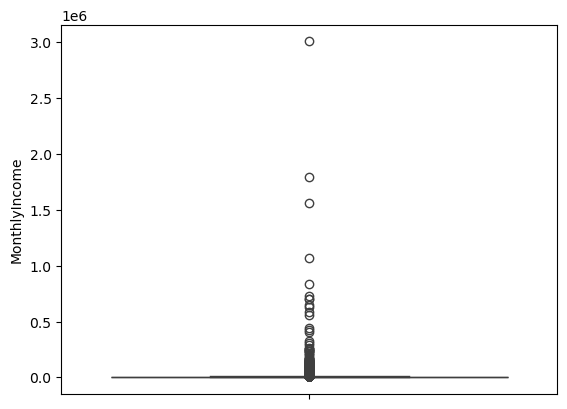

In [16]:
sns.boxplot(df['MonthlyIncome'])

In [17]:
df[df['MonthlyIncome'] > 500000] [[
    'MonthlyIncome',
    'DebtRatio',
    'NumberOfOpenCreditLinesAndLoans',
    'NumberRealEstateLoansOrLines',
    'RevolvingUtilizationOfUnsecuredLines',
    'SeriousDlqin2yrs'
]].sort_values(by='MonthlyIncome',ascending=False)

,MonthlyIncome,DebtRatio,NumberOfOpenCreditLinesAndLoans,NumberRealEstateLoansOrLines,RevolvingUtilizationOfUnsecuredLines,SeriousDlqin2yrs
73763,3008750.0,0.001470,10,1,0.007328,0
137140,1794060.0,0.002776,15,1,0.000000,0
111365,1560100.0,0.004013,12,4,0.163856,0
50640,1072500.0,0.004537,9,2,0.469025,0
122543,835040.0,0.000147,8,0,0.041599,0
123291,730483.0,0.005570,23,1,0.226333,0
93564,702500.0,0.008268,12,4,0.071628,0
96549,699530.0,0.003698,11,2,0.064155,0
119136,649587.0,0.001313,8,0,0.151329,0
37078,629000.0,0.000000,3,0,0.000000,0


##### the high values in MonthlyIncome 
are not considered data errors or invalid outliers
they may represent high income or VIP customers 

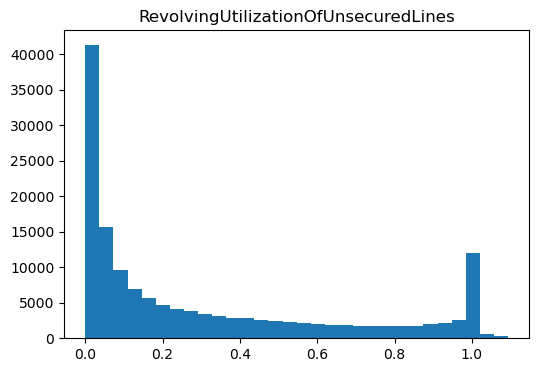

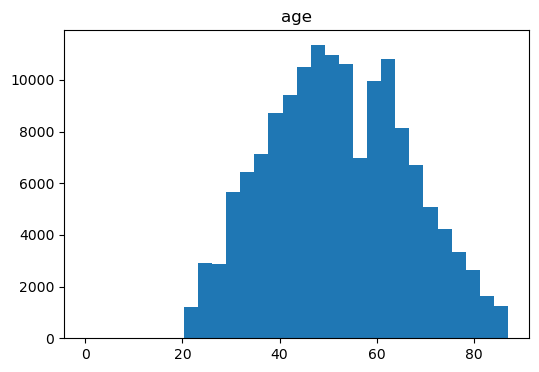

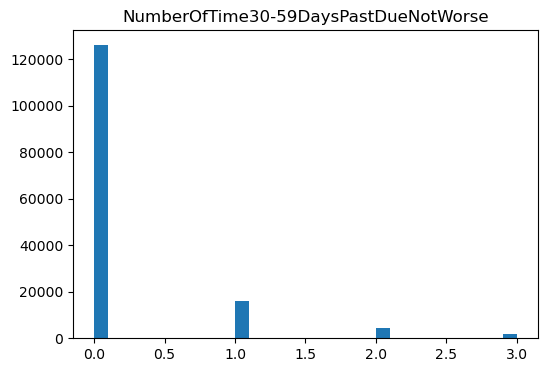

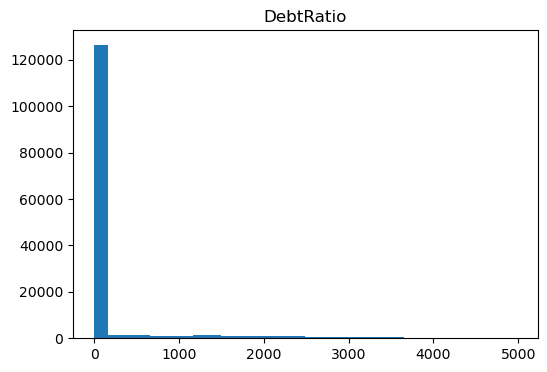

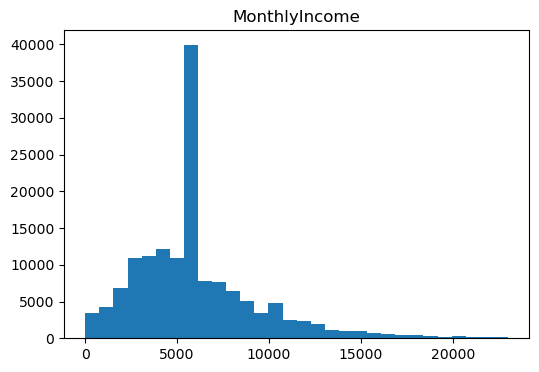

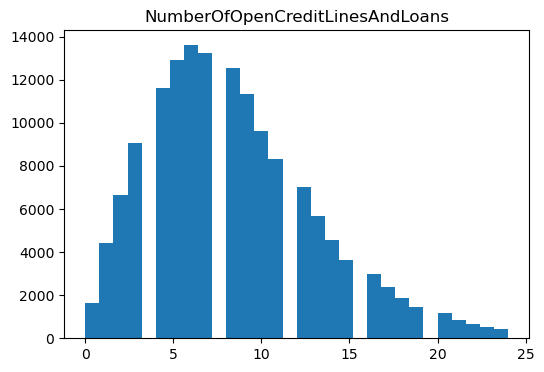

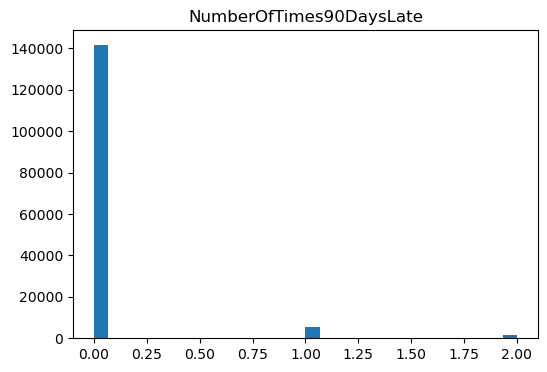

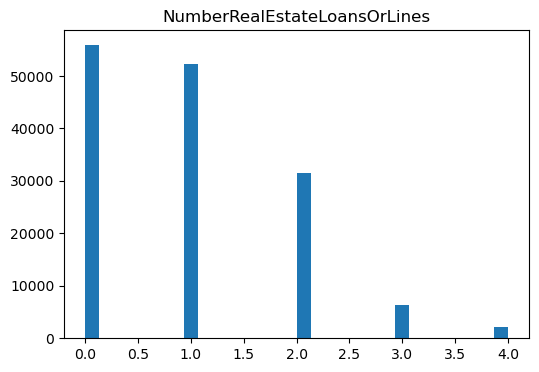

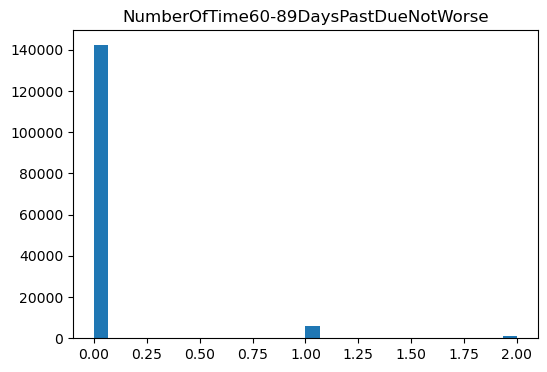

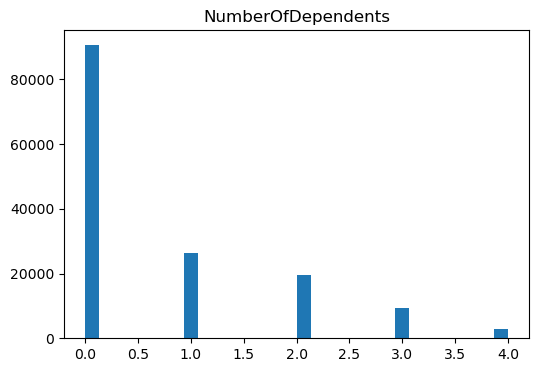

In [18]:
for col in df.drop(columns='SeriousDlqin2yrs'):
    plt.figure(figsize=(6,4))

   
    plt.hist(df[df[col] <= df[col].quantile(0.99)][col], bins=30)
    

    plt.title(col)
    plt.show()

<Axes: xlabel='age', ylabel='Count'>

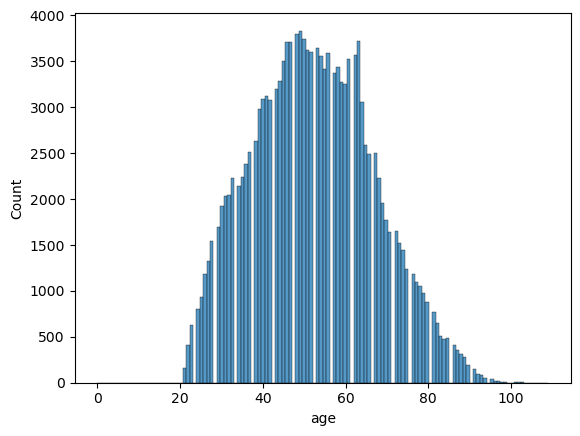

In [19]:
sns.histplot(df['age'])

In [20]:
df.describe()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
count,149731.000000,149731.000000,149731.000000,149731.000000,149731.000000,1.497310e+05,149731.000000,149731.000000,149731.000000,149731.000000,149731.000000
mean,0.065978,6.057508,52.327634,0.245794,353.628957,6.423095e+03,8.467932,0.090456,1.020069,0.064823,0.738150
std,0.248245,249.979529,14.754942,0.697780,2039.594737,1.290108e+04,5.138094,0.485527,1.129960,0.330073,1.107375
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.029771,41.000000,0.000000,0.175998,3.915000e+03,5.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.153491,52.000000,0.000000,0.367119,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000
75%,0.000000,0.555601,63.000000,0.000000,0.870021,7.400000e+03,11.000000,0.000000,2.000000,0.000000,1.000000
max,1.000000,50708.000000,109.000000,13.000000,329664.000000,3.008750e+06,58.000000,17.000000,54.000000,11.000000,20.000000


In [21]:
df=df[df['age']>=18]

<Axes: ylabel='RevolvingUtilizationOfUnsecuredLines'>

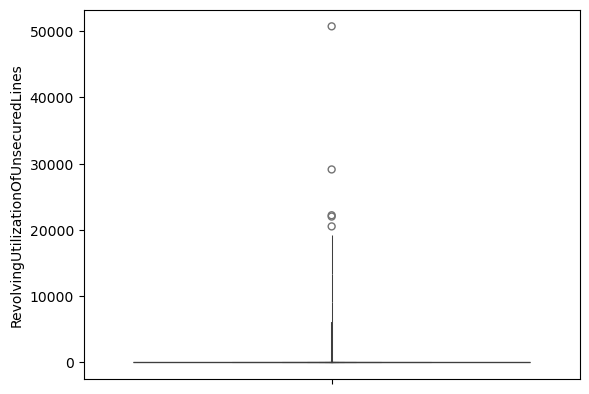

In [22]:
sns.boxenplot(df['RevolvingUtilizationOfUnsecuredLines'])

In [23]:
print((df['RevolvingUtilizationOfUnsecuredLines']>5).sum())
print((df['RevolvingUtilizationOfUnsecuredLines']>5).sum()/df.shape[0])
df=df[df['RevolvingUtilizationOfUnsecuredLines']<5]

254
0.0016963868296266612


##### A total of 254 records (0.17% of the dataset) had RevolvingUtilizationOfUnsecuredLines values greater than 5.
Since this feature represents a credit utilization ratio, these values are extremely high compared to the expected range and may negatively affect model performance. Due to their very small proportion, these records were removed during data preprocessing.



<Axes: ylabel='DebtRatio'>

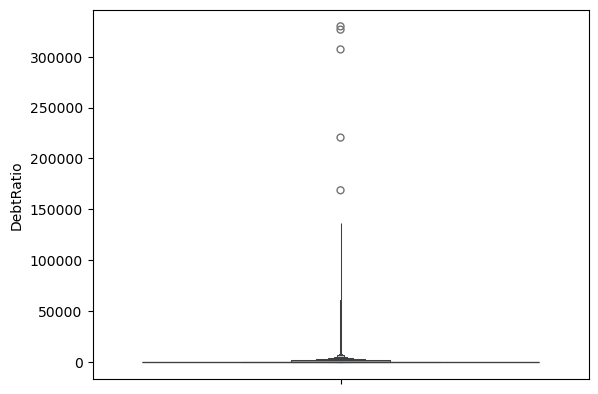

In [24]:
sns.boxenplot(df['DebtRatio'])


In [25]:
df[df['DebtRatio']>100][[
    'DebtRatio','MonthlyIncome','NumberOfOpenCreditLinesAndLoans','NumberRealEstateLoansOrLines'
]].sort_values(by='DebtRatio',ascending=False).head(20)

,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberRealEstateLoansOrLines
60152,329664.0,5400.0,9,3
36600,326442.0,5400.0,6,1
127047,307001.0,5400.0,16,4
58900,220516.0,5400.0,8,3
4854,168835.0,5400.0,10,3
7513,110952.0,5400.0,9,0
103041,106885.0,5400.0,8,4
69845,101320.0,5400.0,12,0
66785,61907.0,5400.0,13,6
53682,61106.5,1.0,2,0


In [26]:
print((df['DebtRatio'] > 100).sum(), round(((df['DebtRatio'] > 100).sum()) / df.shape[0] * 100), "%")
print((df['DebtRatio'] > 1000).sum(), round(((df['DebtRatio'] > 1000).sum()) / df.shape[0] * 100), "%")
print((df['DebtRatio'] > 10000).sum(), ((df['DebtRatio'] > 10000).sum()) / df.shape[0] * 100, "%")




24314 16 %
16847 11 %
179 0.11975166581926196 %


##### Although DebtRatio contains extreme values, they were not removed. 
About 16.2% of the records have values above 100, 11.2% exceed 1,000, and 0.12% exceed 10,000. As these values represent a significant portion of the dataset and there is no evidence that they are erroneous, 
they were retained for model training.

<Axes: ylabel='NumberOfOpenCreditLinesAndLoans'>

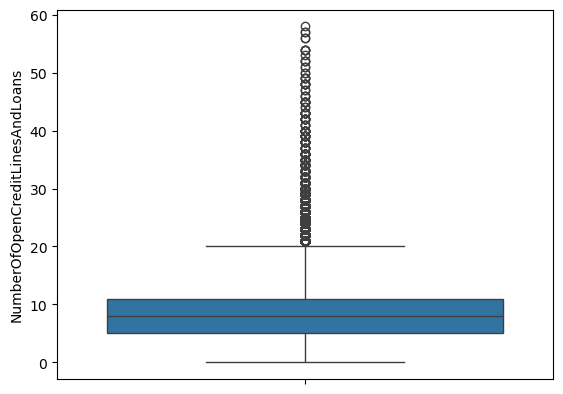

In [27]:
sns.boxplot(df['NumberOfOpenCreditLinesAndLoans'])

<Axes: ylabel='NumberRealEstateLoansOrLines'>

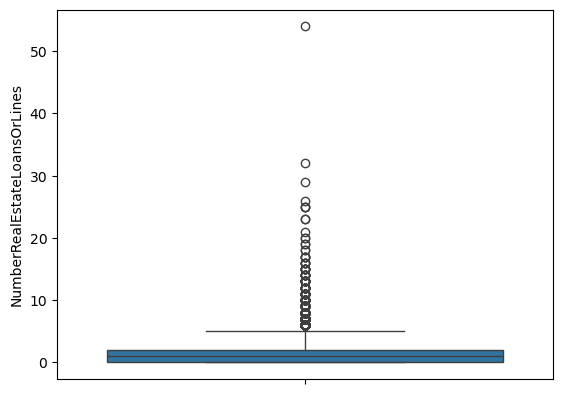

In [28]:
sns.boxplot(df['NumberRealEstateLoansOrLines'])

In [29]:
df[df['NumberRealEstateLoansOrLines']>20][['DebtRatio','MonthlyIncome',
'NumberOfOpenCreditLinesAndLoans',
'NumberRealEstateLoansOrLines']].sort_values(by='NumberRealEstateLoansOrLines')

,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberRealEstateLoansOrLines
31517,0.505055,33334.0,29,21
46102,52112.000000,5400.0,27,23
62192,3.593683,14500.0,26,23
68909,1.237481,12400.0,42,25
103893,0.467231,37000.0,33,25
123746,0.515205,56000.0,42,25
18259,0.429449,48000.0,33,26
65728,0.719174,55966.0,41,29
104198,1.041757,70000.0,38,32
30587,5.967504,8000.0,58,54


##### Although NumberRealEstateLoansOrLines contains a few high values,
they were retained because they are consistent with other financial features, such as a high number of open credit accounts and, 
in many cases, high monthly income. Therefore, there is no evidence that these observations are invalid or erroneous.

In [30]:
df.describe()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
count,149476.000000,149476.000000,149476.000000,149476.000000,149476.000000,1.494760e+05,149476.000000,149476.000000,149476.000000,149476.000000,149476.000000
mean,0.065957,0.321023,52.331538,0.245852,353.208831,6.421101e+03,8.472544,0.090476,1.019809,0.064780,0.738313
std,0.248208,0.361642,14.754216,0.697882,2039.977594,1.290976e+04,5.139671,0.485360,1.130064,0.329573,1.107525
min,0.000000,0.000000,21.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.029676,41.000000,0.000000,0.175928,3.910000e+03,5.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.152672,52.000000,0.000000,0.367083,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000
75%,0.000000,0.552338,63.000000,0.000000,0.869027,7.400000e+03,11.000000,0.000000,2.000000,0.000000,1.000000
max,1.000000,4.937063,109.000000,13.000000,329664.000000,3.008750e+06,58.000000,17.000000,54.000000,11.000000,20.000000


## 4. 📈 Exploratory Data Analysis (EDA)
* 1. Univariate Analysis
   • Target Analysis
   • Numerical Features
   • Count Features

* 2. Bivariate Analysis
   • Numerical vs Target
   • Count Features vs Target
   • Correlation Analysis

* 3. Multivariate Analysis
   • Correlation Heatmap
   • Pairplot
   • Scatter Plots
   • Feature Relationships

#### 1. Univariate Analysis
* 1   • Target Analysis
* 2  • Numerical Features
* 3   • Count Features

SeriousDlqin2yrs
0    139617
1      9859
Name: count, dtype: int64


Text(0.5, 1.0, 'Distribution of Target Variable')

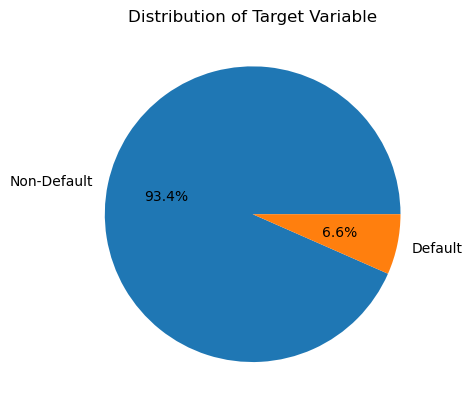

In [31]:
x=df['SeriousDlqin2yrs'].value_counts()
print (x)
la=df['SeriousDlqin2yrs'].value_counts().index
plt.pie(x,labels=['Non-Default', 'Default'],autopct="%1.1f%%")
plt.title('Distribution of Target Variable')


([<matplotlib.axis.XTick at 0x246d8417890>,
 [Text(0, 0, 'Non-Default'), Text(1, 0, 'Default')])

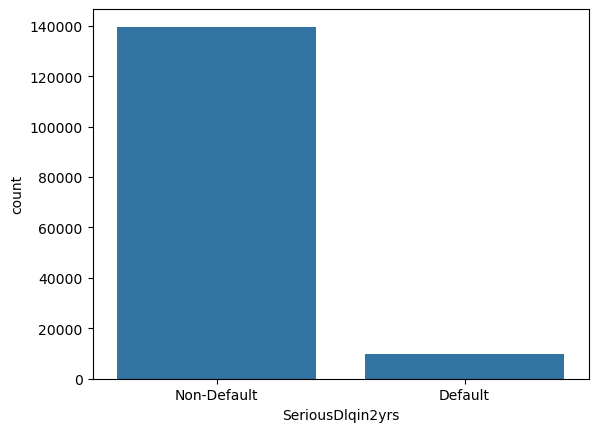

In [32]:
sns.countplot(data=df,x='SeriousDlqin2yrs')
plt.xticks(
    ticks=[0, 1],
    labels=['Non-Default', 'Default'])


##### 📌 Note:
* Approximately  139618  ~ 93.3% of customers did not experience serious delinquency, while only  9859  ~ 6.7% defaulted. This indicates that default events are relatively rare, which should be considered during model training and evaluation

In [33]:
numerical_features = [
    'RevolvingUtilizationOfUnsecuredLines',
    'age',
    'DebtRatio',
    'MonthlyIncome'
]

Text(0.5, 1.0, 'RevolvingUtilizationOfUnsecuredLines')

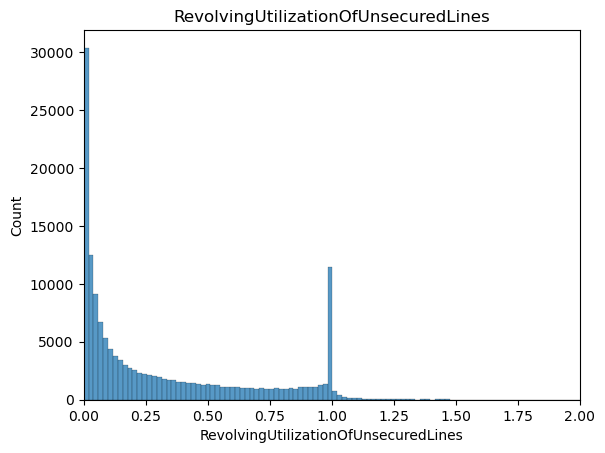

In [34]:
sns.histplot(df['RevolvingUtilizationOfUnsecuredLines'])
plt.xlim(0,2)
plt.title('RevolvingUtilizationOfUnsecuredLines')

###### 📌 Note:
* RevolvingUtilizationOfUnsecuredLines is highly right-skewed. Most customers use a small portion of their available unsecured credit, while a noticeable number fully utilize their credit limit (1.0). Extremely unrealistic values (>5) were removed during data cleaning because they are inconsistent with a utilization ratio.

<Axes: xlabel='age', ylabel='Count'>

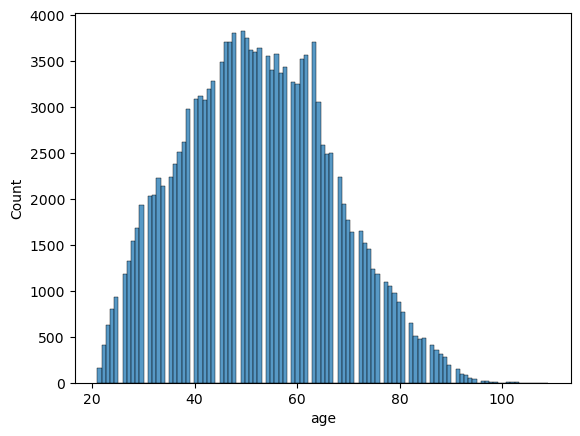

In [35]:
sns.histplot(df['age'])

###### 📌 Note:
* Most customers are between 40 and 65 years old, indicating that the dataset is primarily composed of middle-aged adults. No abnormal age values were identified.

(0.0, 30000.0)

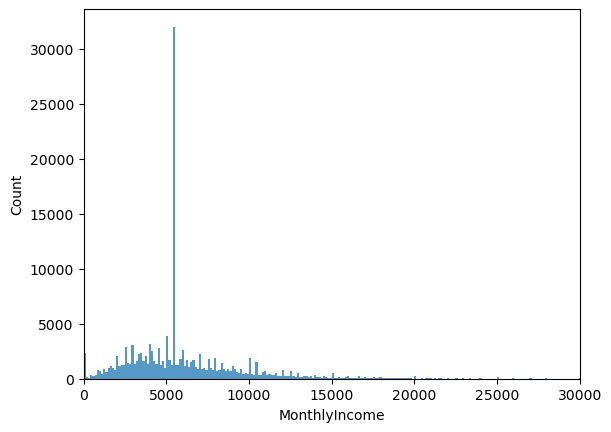

In [36]:
sns.histplot(df['MonthlyIncome'])
plt.xlim(0,30000)

###### 📌 Note:
*  The MonthlyIncome distribution is positively skewed. Most customers have a monthly income between 3,000 and 8,000, with a noticeable peak around 5,500–6,000. The number of customers decreases as income increases, while only a small proportion of customers have very high monthly income

In [37]:
df['DebtRatio'].describe()

count    149476.000000
mean        353.208831
std        2039.977594
min           0.000000
25%           0.175928
50%           0.367083
75%           0.869027
max      329664.000000
Name: DebtRatio, dtype: float64

(0.0, 10.0)

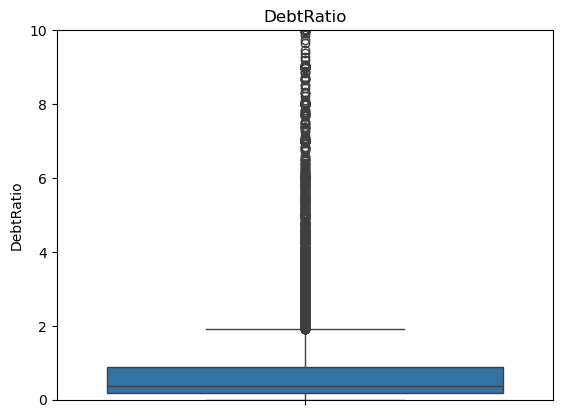

In [38]:
sns.boxplot(df['DebtRatio'])
plt.title('DebtRatio')
plt.ylim(0,10)

###### 📌 Note:
* DebtRatio is highly right-skewed with many outliers. These values were retained because they appear to be valid and show no evidence of data entry errors.

In [39]:
count_features = [
    'NumberOfTime30-59DaysPastDueNotWorse',
    'NumberOfOpenCreditLinesAndLoans',
    'NumberOfTimes90DaysLate',
    'NumberRealEstateLoansOrLines',
    'NumberOfTime60-89DaysPastDueNotWorse',
    'NumberOfDependents'
]

In [40]:
df['NumberOfTimes90DaysLate'].describe()

count    149476.000000
mean          0.090476
std           0.485360
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max          17.000000
Name: NumberOfTimes90DaysLate, dtype: float64

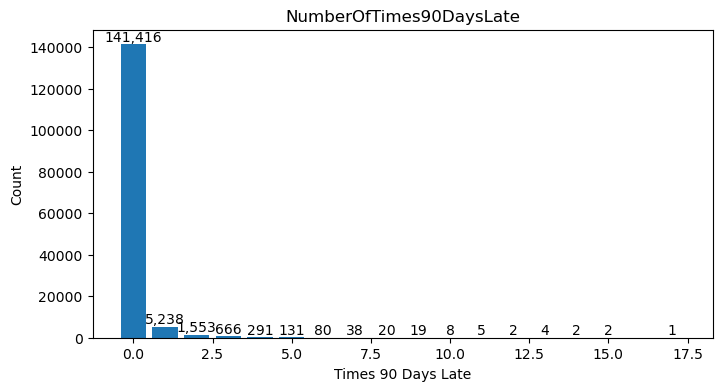

In [41]:
counts = df['NumberOfTimes90DaysLate'].value_counts().sort_index()

plt.figure(figsize=(8,4))
bars = plt.bar(counts.index, counts.values)

for bar, value in zip(bars, counts.values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value,
        f'{value:,}',
        ha='center',
        va='bottom',
        fontsize=10
    )

plt.xlabel('Times 90 Days Late')
plt.ylabel('Count')
plt.title('NumberOfTimes90DaysLate')

plt.show()

NumberOfTimes90DaysLate
0     141416
1       5238
2       1553
3        666
4        291
5        131
6         80
7         38
8         20
9         19
10         8
11         5
12         2
13         4
14         2
15         2
17         1
Name: count, dtype: int64


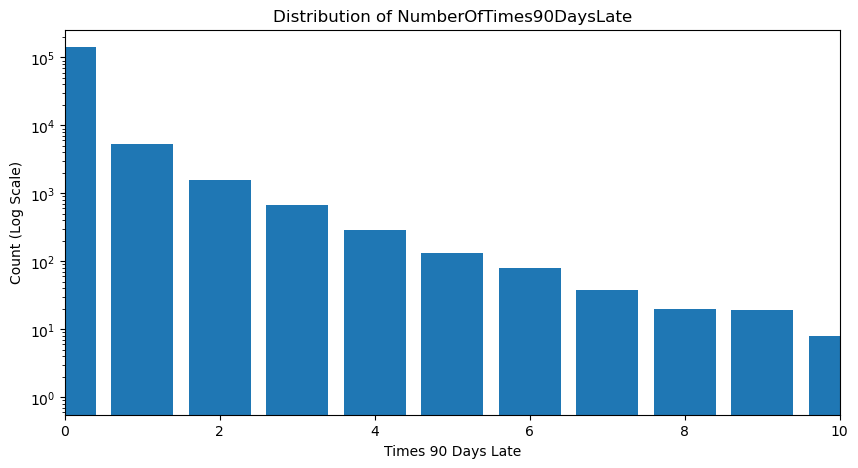

In [42]:
counts = df['NumberOfTimes90DaysLate'].value_counts().sort_index()
print(counts)
plt.figure(figsize=(10,5))
plt.bar(counts.index, counts.values)

plt.yscale('log')

plt.xlabel('Times 90 Days Late')
plt.ylabel('Count (Log Scale)')
plt.title('Distribution of NumberOfTimes90DaysLate')
plt.xlim(0,10)

plt.show()

###### 📌 Note:
* Approximately 94.3% of customers have never been 90 days late on a payment. About 3.5% were late once, 1.0% were late twice, while customers with three or more serious late payments account for less than 1.2% of the dataset. This shows that repeated severe delinquency is rare.

NumberOfTime30-59DaysPastDueNotWorse
0     125794
1      16019
2       4586
3       1750
4        746
5        342
6        140
7         54
8         25
9         12
10         4
12         2
13         1
11         1
Name: count, dtype: int64


Text(0.5, 1.0, 'NumberOfTime30-59DaysPastDueNotWorse')

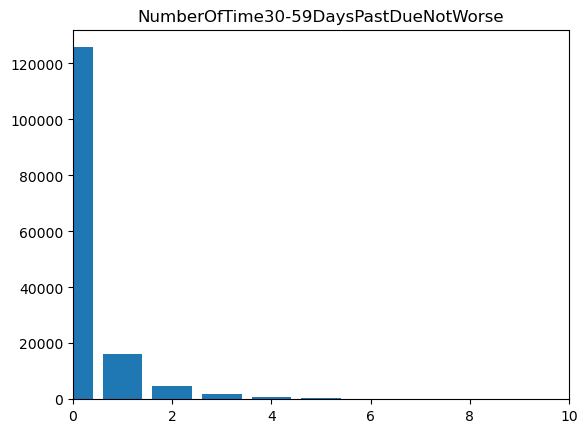

In [43]:
x=df['NumberOfTime30-59DaysPastDueNotWorse'].value_counts()
la=df['NumberOfTime30-59DaysPastDueNotWorse'].value_counts().index
print (x)
plt.bar(la,x)
plt.xlim(0,10)
plt.title('NumberOfTime30-59DaysPastDueNotWorse')


In [44]:
df['NumberOfTime30-59DaysPastDueNotWorse'].value_counts()

NumberOfTime30-59DaysPastDueNotWorse
0     125794
1      16019
2       4586
3       1750
4        746
5        342
6        140
7         54
8         25
9         12
10         4
12         2
13         1
11         1
Name: count, dtype: int64

###### 📌 Note:
* Most customers have no 90-day late payments. The number of customers decreases as the number of late payments increases, indicating that repeated serious delinquency is relatively uncommon. No abnormal values were observed after data cleaning.

In [45]:
df.head()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


NumberOfDependents
0.0     90441
1.0     26256
2.0     19470
3.0      9462
4.0      2857
5.0       745
6.0       158
7.0        51
8.0        24
10.0        5
9.0         5
20.0        1
13.0        1
Name: count, dtype: int64


(0.0, 10.0)

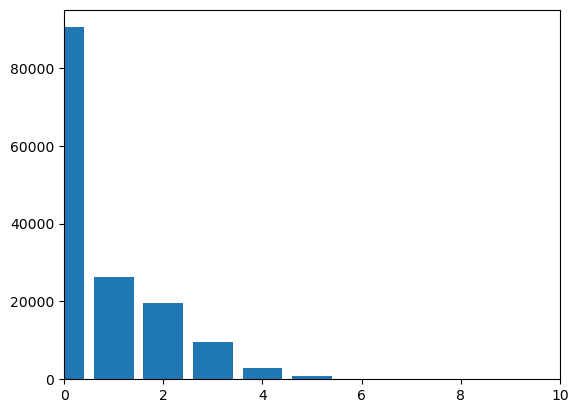

In [46]:
v=df['NumberOfDependents'].value_counts()
print(v)
lab=df['NumberOfDependents'].value_counts().index
plt.bar(lab,v)
plt.xlim(0,10)


###### 📌 Note:
* Most customers have no or only one real estate loan. The frequency decreases as the number of real estate loans increases, indicating that customers with multiple properties are relatively uncommon. No abnormal values were observed.

NumberRealEstateLoansOrLines
0    55850
1    52238
2    31452
3     6288
4     2169
5      687
6      320
7      171
8       93
9       77
Name: count, dtype: int64


(0.0, 10.0)

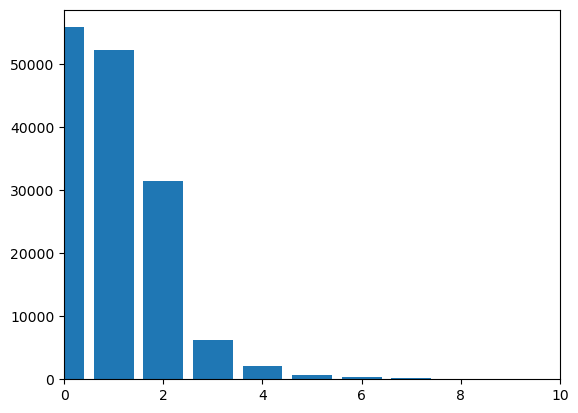

In [47]:
c=df['NumberRealEstateLoansOrLines'].value_counts()
print(c.head(10))
cv=df['NumberRealEstateLoansOrLines'].value_counts().index
plt.bar(cv,c)
plt.xlim(0,10)

### 2. Bivariate Analysis
   • Numerical vs Target
   • Count Features vs Target
   • Correlation Analysis

SeriousDlqin2yrs
0    0.294095
1    0.702364
Name: RevolvingUtilizationOfUnsecuredLines, dtype: float64


<Axes: xlabel='SeriousDlqin2yrs', ylabel='RevolvingUtilizationOfUnsecuredLines'>

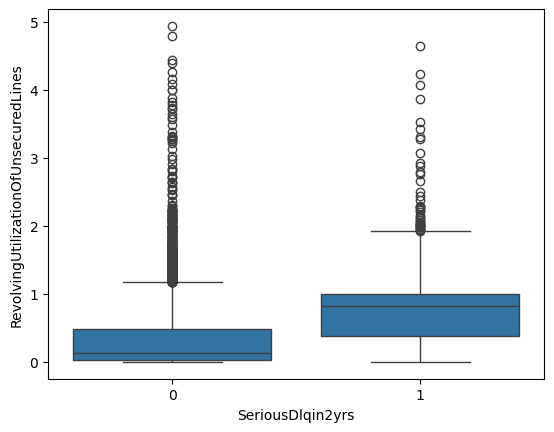

In [48]:
gr=df.groupby('SeriousDlqin2yrs')['RevolvingUtilizationOfUnsecuredLines'].mean()
print(gr)
sns.boxplot(
    data=df,
    x='SeriousDlqin2yrs',
    y='RevolvingUtilizationOfUnsecuredLines'
    
)

###### 📌 Note:
* The average revolving credit utilization is 29.4% for non-default customers and 70.2% for default customers. This indicates that customers who default tend to use a significantly larger portion of their available unsecured credit. The box plot and summary statistics both suggest that higher credit utilization is associated with an increased risk of default.

                        mean    median
SeriousDlqin2yrs                      
0                 357.130370  0.362909
1                 297.674445  0.431982


<Axes: xlabel='SeriousDlqin2yrs', ylabel='DebtRatio'>

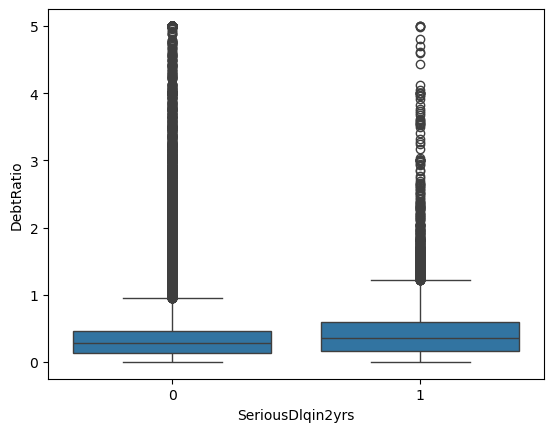

In [49]:
gr=df.groupby('SeriousDlqin2yrs')['DebtRatio'].agg(['mean', 'median'])
print(gr)
sns.boxplot(
    data=df[df['DebtRatio'] <= 5],
    x='SeriousDlqin2yrs',
    y='DebtRatio'
)

<Axes: xlabel='SeriousDlqin2yrs', ylabel='MonthlyIncome'>

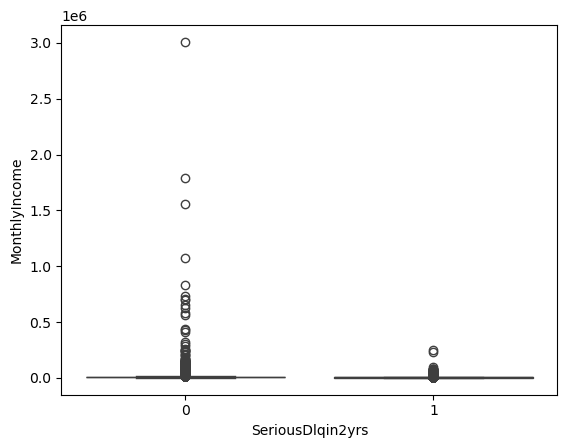

In [50]:
sns.boxplot(
    data=df,
    x='SeriousDlqin2yrs',
    y='MonthlyIncome'
)

<Axes: xlabel='NumberOfTimes90DaysLate', ylabel='count'>

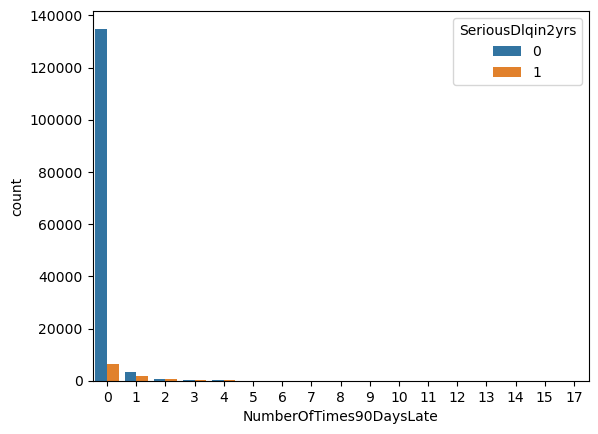

In [51]:
sns.countplot(
    data=df,
    x='NumberOfTimes90DaysLate',
    hue='SeriousDlqin2yrs'
)

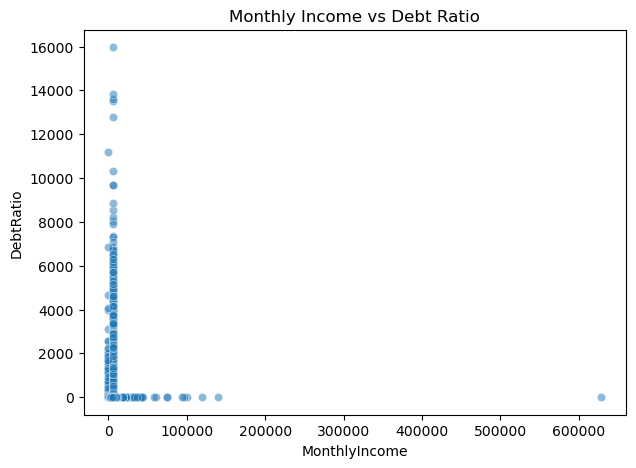

In [52]:
sample = df.sample(5000, random_state=42)

plt.figure(figsize=(7,5))

sns.scatterplot(
    data=sample,
    x='MonthlyIncome',
    y='DebtRatio',
    alpha=0.5
)

plt.title('Monthly Income vs Debt Ratio')
plt.show()

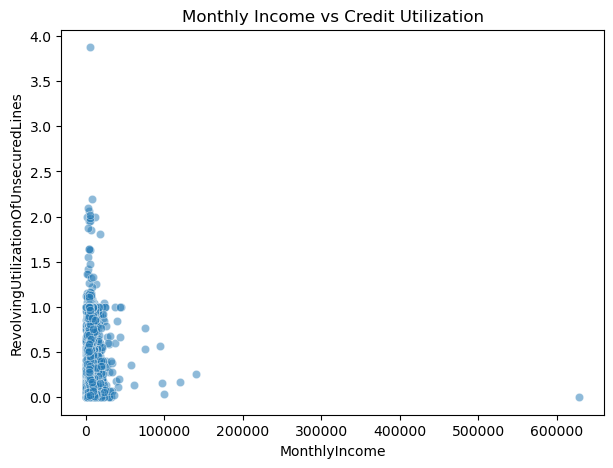

In [53]:
sample = df.sample(5000, random_state=42)

plt.figure(figsize=(7,5))

sns.scatterplot(
    data=sample,
    x='MonthlyIncome',
    y='RevolvingUtilizationOfUnsecuredLines',
    alpha=0.5
)

plt.title('Monthly Income vs Credit Utilization')
plt.show()

### 3. Multivariate Analysis
   • Correlation Heatmap
   • Pairplot
   • Scatter Plots

<Axes: >

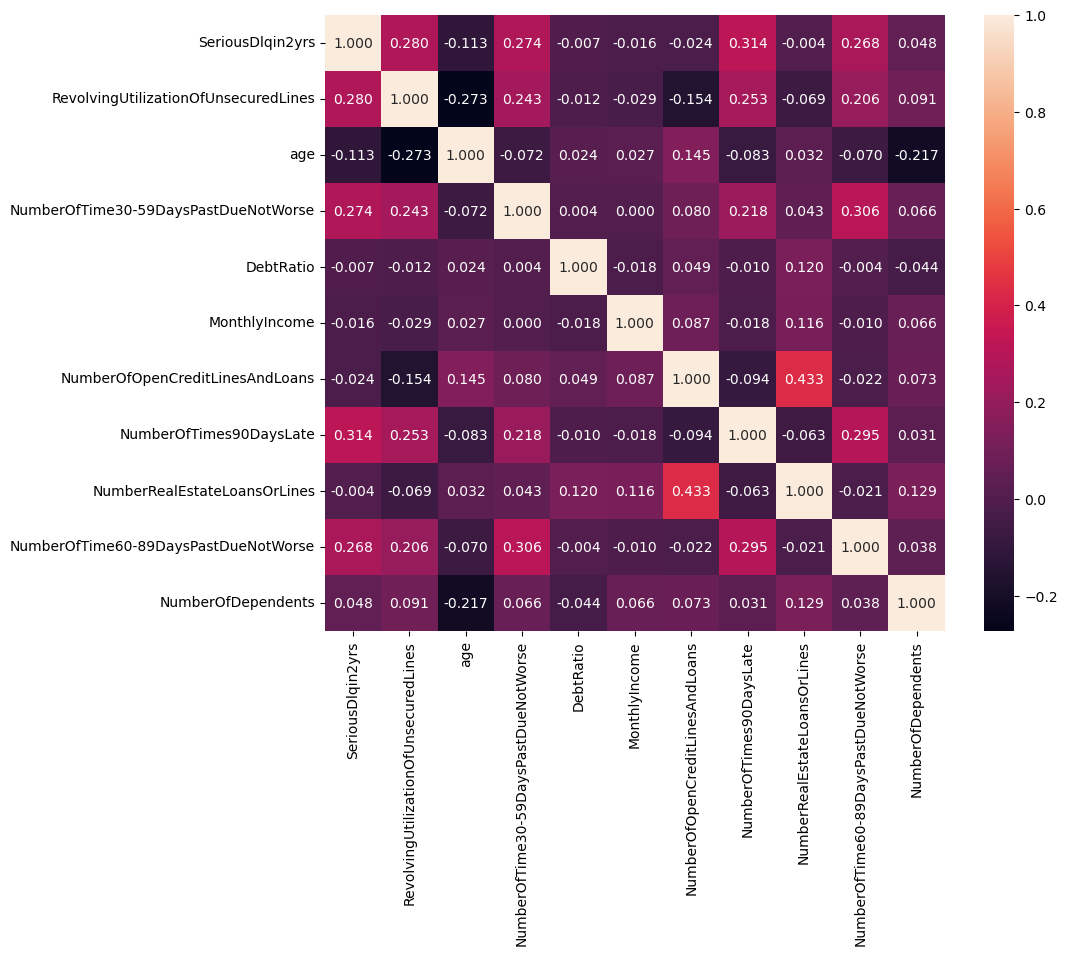

In [54]:
plt.figure(figsize=(10,8))
cor=df.corr()
sns.heatmap(cor,annot=True,fmt='.3f')

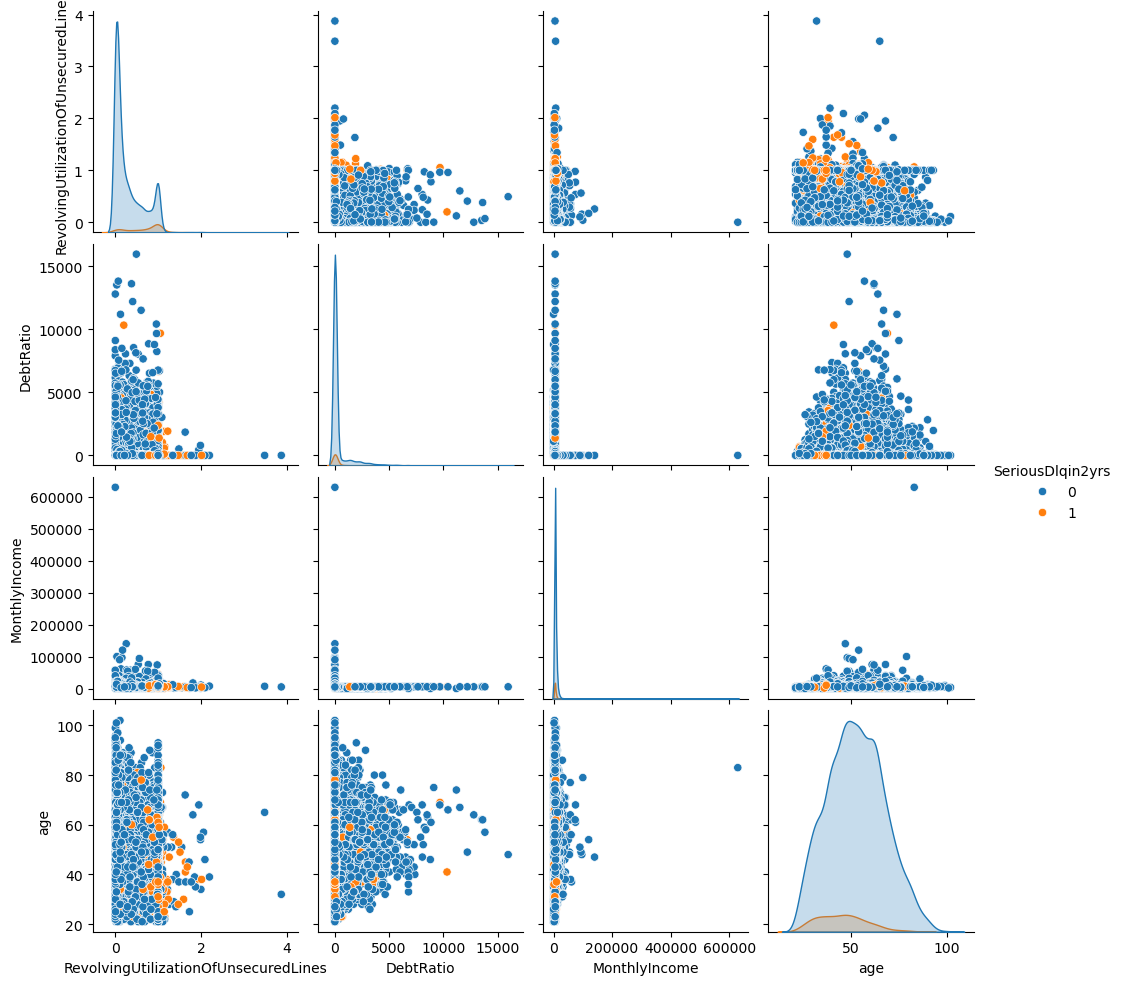

In [55]:
cols = [
    'RevolvingUtilizationOfUnsecuredLines',
    'DebtRatio',
    'MonthlyIncome',
    'age',
    'SeriousDlqin2yrs'
]
sns.pairplot(df[cols].sample(10000,random_state=42),hue='SeriousDlqin2yrs')

## 5.💾 save clean data 


In [56]:
from pathlib import Path


PROJECT_PATH = Path(r"C:\Users\SAMA\Desktop\pank_project")


DATA_PATH = PROJECT_PATH / "credit_risk_cleaned.csv"


df.to_csv(DATA_PATH, index=False)

print("Data saved successfully:", DATA_PATH)



Data saved successfully: C:\Users\SAMA\Desktop\pank_project\credit_risk_cleaned.csv


## 6. ⚙️ Feature Engineering

###  Feature Encoding
* The dataset contains only numerical features, and the target variable is already binary encoded (0 = Non-Default, 1 = Default). Therefore, no feature encoding was required.

### ✂️ Splitting Data

In [57]:
from sklearn .model_selection import train_test_split
x=df.drop('SeriousDlqin2yrs',axis=1)
y=df['SeriousDlqin2yrs']

from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    x, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.333,
    random_state=42,
    stratify=y_temp
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)


Training: (112107, 10)
Validation: (24925, 10)
Testing: (12444, 10)


## 7.💾 Save Test Data

In [58]:

PROJECT_PATH = Path(r"C:\Users\SAMA\Desktop\pank_project")

FEATURES = [
    'RevolvingUtilizationOfUnsecuredLines',
    'age',
    'NumberOfTime30-59DaysPastDueNotWorse',
    'DebtRatio',
    'MonthlyIncome',
    'NumberOfOpenCreditLinesAndLoans',
    'NumberOfTimes90DaysLate',
    'NumberRealEstateLoansOrLines',
    'NumberOfTime60-89DaysPastDueNotWorse',
    'NumberOfDependents'
]

# Prepare test data
test_df = X_test.copy()

if not isinstance(test_df, pd.DataFrame):
    test_df = pd.DataFrame(test_df, columns=FEATURES)

test_df = test_df[FEATURES].copy()

# Add actual target
test_df["SeriousDlqin2yrs"] = np.asarray(y_test).reshape(-1)

# Save inside project folder
test_path = PROJECT_PATH / "credit_risk_test.csv"

test_df.to_csv(test_path, index=False)

print("Test dataset saved successfully!")
print("File location:", test_path)
print("Dataset shape:", test_df.shape)


Test dataset saved successfully!
File location: C:\Users\SAMA\Desktop\pank_project\credit_risk_test.csv
Dataset shape: (12444, 11)


### Feature Scaling&& Pipeline

In [59]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
pipeline =Pipeline([
    ("scaler",StandardScaler())])
scal=StandardScaler()
X_train=pipeline.fit_transform(X_train)
X_test=pipeline.transform(X_test)
X_val=pipeline.transform(X_val)

In [60]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)



X_train: (112107, 10)
y_train: (112107,)


## 8.🤖Model Deep Learning

In [61]:
import keras
from keras.models import Sequential
from keras.layers import Dense,Dropout

In [62]:
ann=Sequential()
ann.add(Dense(units=6,activation="sigmoid")) #1st hidden layer
ann.add(Dense(units=6,activation='relu')) #2nd hidden layer
ann.add(Dense(units=1,activation='sigmoid')) # output layer

In [63]:
ann.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [64]:
early_stop = keras.callbacks.EarlyStopping(patience=5,min_delta=0.0005, restore_best_weights=True)
ann.fit(X_train,y_train,validation_data=(X_val, y_val),batch_size=32,epochs=20,callbacks=[early_stop])

Epoch 1/20
3504/3504 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step - accuracy: 0.9366 - loss: 0.1953 - val_accuracy: 0.9366 - val_loss: 0.1755
Epoch 2/20
3504/3504 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - accuracy: 0.9374 - loss: 0.1799 - val_accuracy: 0.9371 - val_loss: 0.1749
Epoch 3/20
3504/3504 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - accuracy: 0.9375 - loss: 0.1797 - val_accuracy: 0.9375 - val_loss: 0.1750
Epoch 4/20
3504/3504 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - accuracy: 0.9371 - loss: 0.1795 - val_accuracy: 0.9373 - val_loss: 0.1746
Epoch 5/20
3504/3504 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - accuracy: 0.9372 - loss: 0.1793 - val_accuracy: 0.9372 - val_loss: 0.1741
Epoch 6/20
3504/3504 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - accuracy: 0.9375 - loss: 0.1791 - val_accuracy: 0.9372 - val_loss: 0.1744
Epoch 7/20
3504/3504 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - accuracy: 0.9372 - loss: 0.1789 - val_accuracy: 0.9377 - val_loss: 0.1740
Epoch 8/20
3504/3504 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - accuracy: 0.9373 - loss: 0.1788 -

In [65]:
print(X_val.shape)

(24925, 10)


In [66]:
y_pred=((ann.predict(X_val))>0.5).astype(int)
pd.Series(y_pred.flatten()).value_counts()

779/779 ━━━━━━━━━━━━━━━━━━━━ 1s 930us/step


0    24386
1      539
Name: count, dtype: int64

In [67]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
cm=confusion_matrix(y_val,y_pred)
print (f"confusion_matrix \n{cm}")
print ("\n******************\n")
print(f"Accuracy = {round(accuracy_score(y_val,y_pred),3)*100}%")
print(classification_report(y_val, y_pred))

confusion_matrix 
[[23051   230]
 [ 1335   309]]

******************

Accuracy = 93.7%
              precision    recall  f1-score   support

           0       0.95      0.99      0.97     23281
           1       0.57      0.19      0.28      1644

    accuracy                           0.94     24925
   macro avg       0.76      0.59      0.63     24925
weighted avg       0.92      0.94      0.92     24925



([<matplotlib.patches.Wedge at 0x246fba8ad50>,
 [Text(-1.0764695329627183, 0.2263036557438426, 'Non-Default'),
  Text(1.0764696067017518, -0.22630330498553491, 'Default')],
 [Text(-0.5871651997978462, 0.12343835767845958, '93.4%'),
  Text(0.5871652400191373, -0.12343816635574631, '6.6%')])

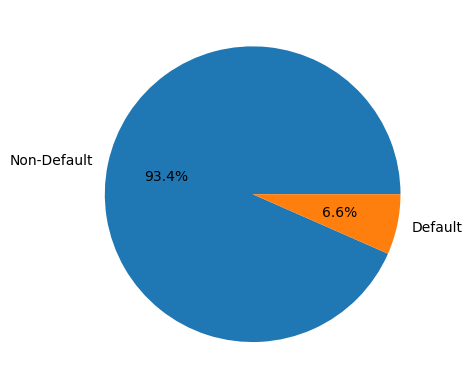

In [68]:
v=df['SeriousDlqin2yrs'].value_counts()
plt.pie(v,labels=['Non-Default', 'Default'],autopct="%1.1f%%")

##### 📌 Note: The dataset is imbalanced, with 93.4% Non-Default cases and only 6.6% Default cases. In the next step, we will handle this class imbalance using class_weights to help the model learn the minority class (Default) more effectively.

In [69]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Class Weights:", class_weights)
class_weights_list=[2.0,3.0,4.0,5.0]
for wei in class_weights_list:
    class_weights={
        0:1.0,
        1:wei   
    }
    print(f"\nWeight for Default = {wei}")
    history = ann.fit(
    X_train,
    y_train,
    batch_size=32,
    epochs=5,
    class_weight=class_weights
    )
    y_pred=((ann.predict(X_val))>0.5).astype(int)
    pd.Series(y_pred.flatten()).value_counts()

    print(confusion_matrix(y_val, y_pred))
    print(classification_report(y_val, y_pred, zero_division=0))
    print (f"\n********************************\n")


Class Weights: {np.int64(0): np.float64(0.5353060269498534), np.int64(1): np.float64(7.580944008655667)}

Weight for Default = 2.0
Epoch 1/5
3504/3504 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.9318 - loss: 0.2845
Epoch 2/5
3504/3504 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.9311 - loss: 0.2839
Epoch 3/5
3504/3504 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.9315 - loss: 0.2837
Epoch 4/5
3504/3504 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.9316 - loss: 0.2836
Epoch 5/5
3504/3504 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.9317 - loss: 0.2834
779/779 ━━━━━━━━━━━━━━━━━━━━ 1s 894us/step
[[22745   536]
 [ 1096   548]]
              precision    recall  f1-score   support

           0       0.95      0.98      0.97     23281
           1       0.51      0.33      0.40      1644

    accuracy                           0.93     24925
   macro avg       0.73      0.66      0.68     24925
weighted avg       0.92      0.93      0.93     24925


********************************

##### 📌 Note: A class weight of 5.0 was selected for further evaluation because it improved the model's Recall for the minority class (Default) to 54%, reducing False Negatives to 917. However, this came at the cost of lower Precision (37%) and more False Positives (1,768). The next step is to evaluate this trade-off on the validation set and fine-tune the classification threshold.

In [70]:
from sklearn.metrics import classification_report, confusion_matrix

y_prob = ann.predict(X_val, verbose=0).ravel()

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

for threshold in thresholds:
    y_pre = (y_prob >= threshold).astype(int)

    print(f"\nThreshold = {threshold}")
    print(f"accurcy is = {round(accuracy_score(y_val,y_pre),2)*100}%\n")
    print(confusion_matrix(y_val, y_pre))
    print(classification_report(y_val, y_pre, zero_division=0))


Threshold = 0.3
accurcy is = 84.0%

[[19607  3674]
 [  433  1211]]
              precision    recall  f1-score   support

           0       0.98      0.84      0.91     23281
           1       0.25      0.74      0.37      1644

    accuracy                           0.84     24925
   macro avg       0.61      0.79      0.64     24925
weighted avg       0.93      0.84      0.87     24925


Threshold = 0.4
accurcy is = 89.0%

[[21083  2198]
 [  594  1050]]
              precision    recall  f1-score   support

           0       0.97      0.91      0.94     23281
           1       0.32      0.64      0.43      1644

    accuracy                           0.89     24925
   macro avg       0.65      0.77      0.68     24925
weighted avg       0.93      0.89      0.90     24925


Threshold = 0.5
accurcy is = 91.0%

[[21768  1513]
 [  716   928]]
              precision    recall  f1-score   support

           0       0.97      0.94      0.95     23281
           1       0.38      0.56

In [71]:
threshold=0.38
y_pre = (y_prob >= threshold).astype(int)

print(f"\nThreshold = {threshold}")
print(f"accurcy is = {round(accuracy_score(y_val,y_pre),2)*100}%\n")
print(confusion_matrix(y_val, y_pre))
print(classification_report(y_val, y_pre, zero_division=0))


Threshold = 0.38
accurcy is = 88.0%

[[20816  2465]
 [  564  1080]]
              precision    recall  f1-score   support

           0       0.97      0.89      0.93     23281
           1       0.30      0.66      0.42      1644

    accuracy                           0.88     24925
   macro avg       0.64      0.78      0.67     24925
weighted avg       0.93      0.88      0.90     24925



##### 📌Note: A classification threshold of 0.38 was selected for further evaluation because it improved the model's Recall for the minority class (Default) to 64%, detecting 1,269 out of 1,977 default cases and reducing False Negatives to 708. However, this came at the cost of lower Precision (30%) and more False Positives (2,897). The next step is to compare nearby thresholds (0.3–0.4) on the validation set to find the best balance between detecting default cases and minimizing false alarms.

In [72]:
y_test_prop=ann.predict(X_test).ravel()

threshold=0.38
y_test_pred=(y_test_prop>=threshold).astype(int)
cm=confusion_matrix(y_test,y_test_pred)
print("when threshold : ",threshold)
print("\nconfusion matrix : ")
print(cm)
print("\n classification_report : ")
print(classification_report(y_test, y_test_pred))
print("\nAccuracy : ",accuracy_score(y_test,y_test_pred))

389/389 ━━━━━━━━━━━━━━━━━━━━ 0s 864us/step
when threshold :  0.38

confusion matrix : 
[[10335  1288]
 [  311   510]]

 classification_report : 
              precision    recall  f1-score   support

           0       0.97      0.89      0.93     11623
           1       0.28      0.62      0.39       821

    accuracy                           0.87     12444
   macro avg       0.63      0.76      0.66     12444
weighted avg       0.93      0.87      0.89     12444


Accuracy :  0.8715043394406943


## 9.💾 Save_Model

In [73]:
import joblib
ann.save("credit_risk_model.keras")
joblib.dump(pipeline,"scaler_pipeline.pkl")

['scaler_pipeline.pkl']

## 10🎯  Load_Model& Prediction

In [74]:
from tensorflow.keras.models import load_model
ann =load_model("credit_risk_model.keras")
pipeline=joblib.load("scaler_pipeline.pkl")

In [77]:
new_data = X_test[[0]]
probability = ann.predict(new_data)          
prediction = (probability > 0.38).astype(int)
print("Default Probability:", probability[0][0])
print("Prediction:", prediction[0][0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
Default Probability: 0.027444772
Prediction: 0


In [78]:
print("Actual:", y_test.iloc[0])

Actual: 0


## 11. 🌐 Deployment
* 🎨 Streamlit App

## 12. 📝 Documentation
* 📖 README
* 📊 Project Report
* 🎥 Demo Video